# Unit 08 — Data Visualization
### Stage 1: Core Foundations | Data Science & AI Program

**Business scenario:** AdventureWorks — a fictional e-commerce company selling electronics, home products, and accessories.

**Audience:** Learners who completed Units 01–07  
**Environment:** Python 3 · Google Colab / Jupyter Notebook  
**Data policy:** Deterministic synthetic business data generated inside this notebook. No external downloads or API keys are required.

> **Instructor note:** The purpose of visualization is not decoration. It is to answer a business question clearly, show relevant patterns, and communicate limitations honestly. This unit introduces Matplotlib and Seaborn using one consistent AdventureWorks dataset.

## Learning outcomes

By the end of this unit, you should be able to:
- Explain when data visualization is useful in exploratory data analysis (EDA).
- Identify a Matplotlib `Figure` and `Axes`, and add titles, labels, legends, and grid lines.
- Choose between line, bar, histogram, and scatter plots for common questions.
- Create Seaborn histograms, boxplots, countplots, and scatterplots.
- Build and interpret a correlation heatmap for numeric variables.
- Improve readability through sorting, clear labels, sensible scales, and appropriate formatting.
- Describe what a chart supports—and what it does not prove.
- Use plots to generate questions for further analysis rather than make unsupported claims.

### Prerequisites
Python fundamentals, Pandas DataFrames, filtering, grouping, and basic descriptive statistics.

### Scope
This unit focuses on introductory visualization and interpretation. Interactive dashboards, advanced statistical graphics, hypothesis testing, and machine-learning model evaluation plots are reserved for later units.

## Table of contents
1. Business questions and dataset
2. Visualization principles and chart selection
3. Matplotlib: Figure, Axes, titles, labels, legends
4. Line chart: trend over time
5. Bar chart: compare categories
6. Histogram: inspect a distribution
7. Scatter plot: explore relationships
8. Seaborn: histogram, boxplot, countplot, scatterplot
9. Correlation heatmap
10. Interpret charts responsibly
11. Integrated AdventureWorks EDA challenge
12. Instructor answer key
13. Summary and readiness checklist

## 1. Business questions and dataset

The AdventureWorks team wants to explore order activity, product categories, order values, and the relationship between quantity and price.

We will generate a small, reproducible dataset with dates, product categories, quantities, unit prices, order statuses, and order values. The numbers are synthetic and are for learning only—not actual company performance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fixed seed makes the synthetic example reproducible.
rng = np.random.default_rng(42)

dates = pd.date_range("2026-09-01", periods=30, freq="D")
daily_orders = pd.DataFrame({
    "order_date": dates,
    "orders": rng.integers(8, 25, size=len(dates)),
    "daily_revenue": np.round(rng.normal(1450, 260, size=len(dates)).clip(650, 2200), 2)
})

products = pd.DataFrame({
    "product": ["Wireless Mouse", "USB-C Hub", "Mechanical Keyboard", "Desk Lamp",
                "Headphones", "Laptop Stand", "Webcam", "Portable SSD"],
    "category": ["Accessories", "Accessories", "Electronics", "Home",
                 "Electronics", "Accessories", "Electronics", "Electronics"],
    "unit_price": [24.99, 34.00, 79.50, 28.75, 59.99, 39.00, 49.50, 89.00]
})

n = 120
product_indices = rng.integers(0, len(products), size=n)
quantity = rng.choice([1, 2, 3, 4], size=n, p=[0.52, 0.28, 0.14, 0.06])
order_dates = rng.choice(dates, size=n)
statuses = rng.choice(["Shipped", "Processing", "Cancelled"], size=n, p=[0.62, 0.28, 0.10])

order_lines = pd.DataFrame({
    "order_id": [f"AW-{6001+i}" for i in range(n)],
    "order_date": order_dates,
    "product": products.loc[product_indices, "product"].to_numpy(),
    "category": products.loc[product_indices, "category"].to_numpy(),
    "quantity": quantity,
    "unit_price": products.loc[product_indices, "unit_price"].to_numpy(),
    "status": statuses
})
order_lines["line_total"] = (order_lines["quantity"] * order_lines["unit_price"]).round(2)

print("Daily summary shape:", daily_orders.shape)
print("Order-line dataset shape:", order_lines.shape)
display(order_lines.head())
display(daily_orders.head())

Daily summary shape: (30, 3)
Order-line dataset shape: (120, 8)


,order_id,order_date,product,category,quantity,unit_price,status,line_total
0,AW-6001,2026-09-18,Portable SSD,Electronics,1,89.0,Shipped,89.0
1,AW-6002,2026-09-17,Mechanical Keyboard,Electronics,1,79.5,Shipped,79.5
2,AW-6003,2026-09-05,USB-C Hub,Accessories,3,34.0,Shipped,102.0
3,AW-6004,2026-09-20,Laptop Stand,Accessories,1,39.0,Processing,39.0
4,AW-6005,2026-09-26,Laptop Stand,Accessories,1,39.0,Shipped,39.0


,order_date,orders,daily_revenue
0,2026-09-01,9,1226.58
1,2026-09-02,21,1545.88
2,2026-09-03,19,1200.69
3,2026-09-04,15,1678.40
4,2026-09-05,15,1437.02


### Data dictionary

| Column | Meaning |
|---|---|
| `order_date` | Date of an order |
| `orders` | Synthetic count of orders for a day |
| `daily_revenue` | Synthetic daily revenue value |
| `product` | Product name |
| `category` | Product category |
| `quantity` | Units in an order line |
| `unit_price` | Price per unit |
| `line_total` | `quantity × unit_price`, before discounts or taxes |
| `status` | Order status |

**Business caution:** `daily_revenue` and the order-line records are independently generated teaching data. Do not join them or assume they reconcile. `line_total` is not official revenue because the data does not model refunds, discounts, tax, or accounting rules.

## 2. Visualization principles and chart selection

Choose a chart based on the question—not because the chart looks attractive.

| Business question | Useful chart | Why |
|---|---|---|
| How does a metric change over time? | Line chart | Shows a trend across ordered dates |
| Which category is larger? | Bar chart | Compares discrete groups |
| How are order values distributed? | Histogram | Shows frequency across value ranges |
| Do two numeric variables move together? | Scatter plot | Shows the relationship between paired values |
| Are distributions different across groups? | Boxplot | Compares medians, spread, and potential outliers |
| How often does each category occur? | Countplot | Compares category counts |
| Which numeric variables are linearly associated? | Correlation heatmap | Summarizes pairwise correlations |

A clear chart usually has a specific title, labeled axes with units, readable tick labels, and a legend only when it adds meaning.

## 3. Matplotlib: Figure, Axes, titles, labels, and legends

Matplotlib is a flexible plotting library. A **Figure** is the overall image or canvas. An **Axes** is the plotting area where data and axis labels are drawn. The object-oriented pattern `fig, ax = plt.subplots()` is a good default because it makes each chart's structure explicit.

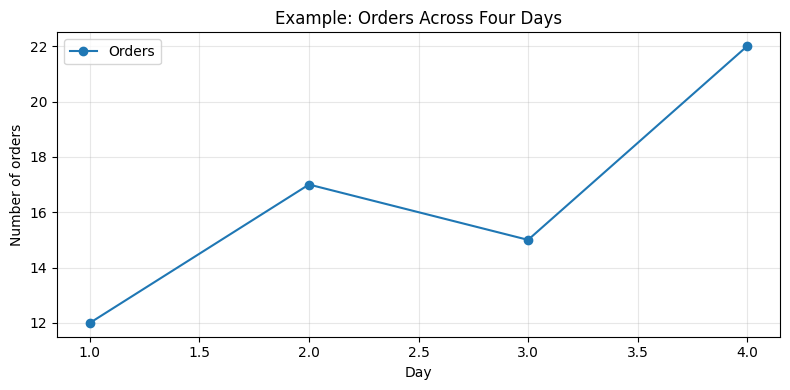

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot([1, 2, 3, 4], [12, 17, 15, 22], marker="o", label="Orders")
ax.set_title("Example: Orders Across Four Days")
ax.set_xlabel("Day")
ax.set_ylabel("Number of orders")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Read the chart:** The x-axis shows the day index and the y-axis shows order counts. The title and labels tell the viewer what is being measured. The legend explains the plotted series.

**Instructor note:** `plt.show()` renders the chart. In notebooks, charts may display automatically, but including it makes the intended output explicit.

## 4. Line chart: trend over time

Use a line chart when the x-axis has a meaningful order, such as dates. Lines help viewers notice increases, decreases, and short-term variation.

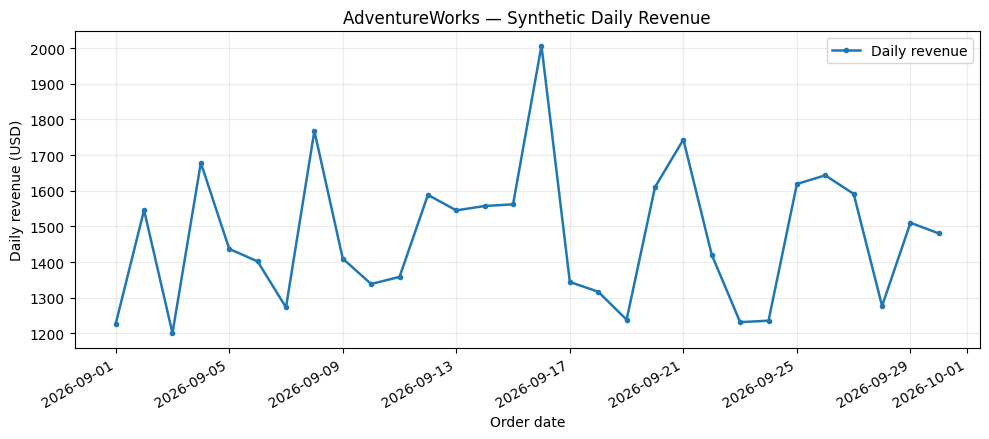

In [12]:
daily_sorted = daily_orders.sort_values("order_date")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(
    daily_sorted["order_date"],
    daily_sorted["daily_revenue"],
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Daily revenue"
)
ax.set_title("AdventureWorks — Synthetic Daily Revenue")
ax.set_xlabel("Order date")
ax.set_ylabel("Daily revenue (USD)")
ax.legend()
ax.grid(True, alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Interpretation prompt**
- On which dates does the line reach a local high or low?
- Does the chart show a steady trend, or mostly day-to-day variation?
- What extra information would you want before explaining why a peak occurred?

A line chart shows a pattern; it does not explain the cause of that pattern.

**Exercise 4A:** Plot `orders` over `order_date` using a line chart. Add a title, axis labels, and a light grid.

## 5. Bar chart: compare categories

A bar chart is useful for comparing values across discrete groups. Sort the bars when ranking is the main goal, and start a bar chart's value axis at zero unless there is a strong, clearly explained reason not to.

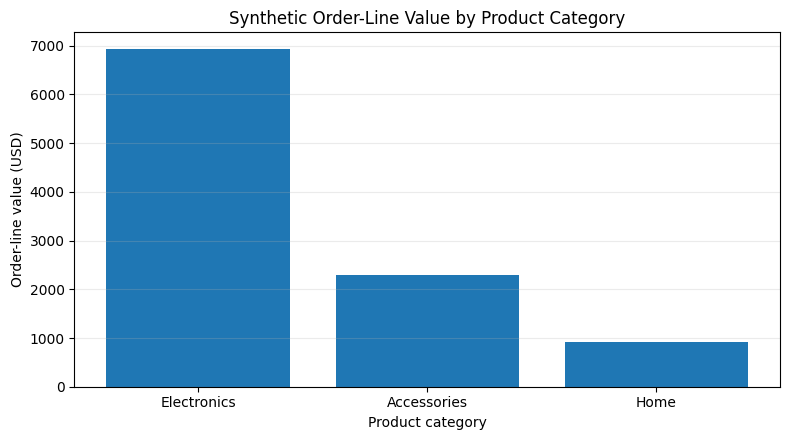

,category,total_units,line_value
1,Electronics,101,6927.35
0,Accessories,70,2300.79
2,Home,32,920.00


In [13]:
category_summary = (
    order_lines.groupby("category", as_index=False)
    .agg(total_units=("quantity", "sum"), line_value=("line_total", "sum"))
    .sort_values("line_value", ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(category_summary["category"], category_summary["line_value"])
ax.set_title("Synthetic Order-Line Value by Product Category")
ax.set_xlabel("Product category")
ax.set_ylabel("Order-line value (USD)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(category_summary)

**Interpretation prompt:** Which category has the highest summed order-line value in this generated sample? Remember that this is line value before discounts and taxes, and order statuses have not been excluded.

**Exercise 5A:** Create a bar chart of total units by product category. Sort the summary from highest to lowest before plotting.

## 6. Histogram: inspect a distribution

A histogram groups numeric values into bins and displays how many observations fall in each bin. Use it to inspect the range, concentration, skew, and possible unusual values of a numeric variable.

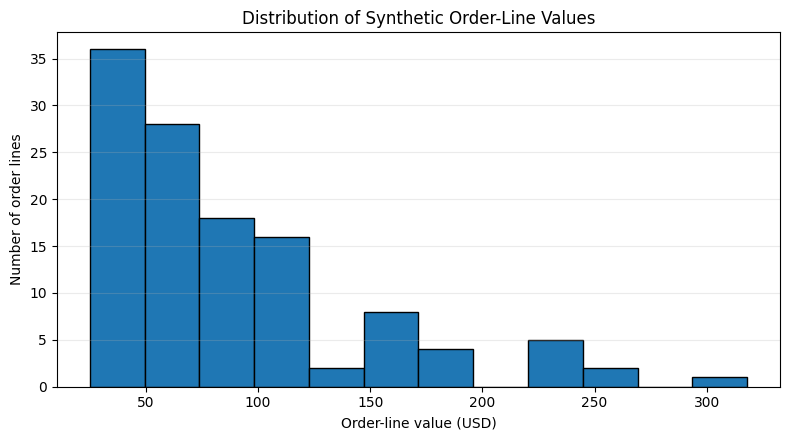

count    120.000000
mean      84.567833
std       61.463044
min       24.990000
25%       39.000000
50%       59.990000
75%      102.000000
max      318.000000
Name: line_total, dtype: float64


In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(order_lines["line_total"], bins=12, edgecolor="black")
ax.set_title("Distribution of Synthetic Order-Line Values")
ax.set_xlabel("Order-line value (USD)")
ax.set_ylabel("Number of order lines")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(order_lines["line_total"].describe())

The shape of a histogram depends partly on the chosen number of bins. Try different values and see how the visual summary changes. Do not treat a bin boundary as a natural business category unless the business has defined it.

**Exercise 6A:** Plot a histogram of `unit_price`. Use a clear title and label the x-axis in USD.

## 7. Scatter plot: explore relationships

A scatter plot represents each observation as a point with an x-value and a y-value. It is useful for exploring whether two numeric variables appear related, whether there are clusters, and whether unusual observations deserve review.

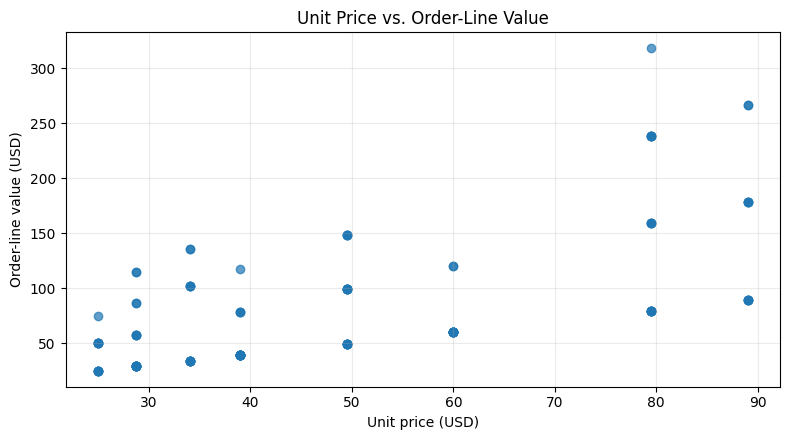

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(order_lines["unit_price"], order_lines["line_total"], alpha=0.7)
ax.set_title("Unit Price vs. Order-Line Value")
ax.set_xlabel("Unit price (USD)")
ax.set_ylabel("Order-line value (USD)")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation prompt:** Since `line_total = quantity × unit_price`, unit price and line total are mathematically connected. The chart alone does not show that higher prices cause higher sales. Quantity is another variable that influences line value.

**Exercise 7A:** Plot `quantity` against `line_total`. Add readable labels and describe one visible pattern without making a causal claim.

## 8. Seaborn: statistical visualizations

Seaborn builds on Matplotlib and provides convenient functions for statistical graphics. It works naturally with DataFrames and can map columns to visual properties such as color. We will use four common plot types: `histplot`, `boxplot`, `countplot`, and `scatterplot`.

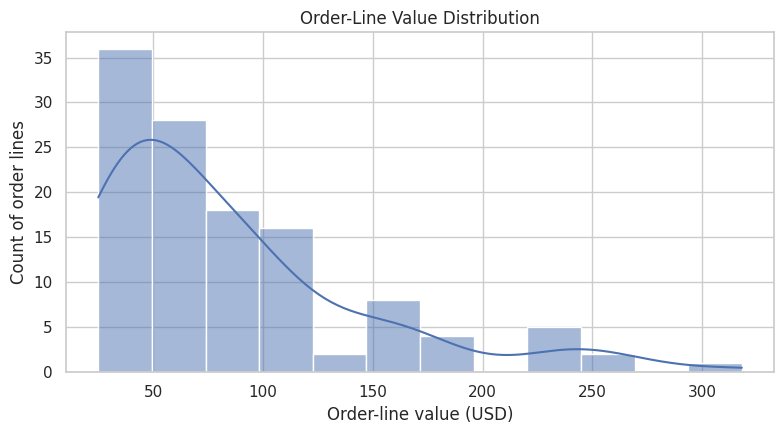

In [16]:
sns.set_theme(style="whitegrid", context="notebook")
sns.set_palette("deep")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=order_lines, x="line_total", bins=12, kde=True, color="C0", ax=ax)
ax.set_title("Order-Line Value Distribution")
ax.set_xlabel("Order-line value (USD)")
ax.set_ylabel("Count of order lines")
plt.tight_layout()
plt.show()

### 8.1 Boxplot: compare distributions across groups

A boxplot summarizes a numeric distribution using its median and quartiles. Points beyond the whiskers may be flagged as potential outliers under the plotting convention; they are not automatically errors.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=order_lines, x="category", y="line_total", ax=ax)
ax.set_title("Order-Line Value by Product Category")
ax.set_xlabel("Product category")
ax.set_ylabel("Order-line value (USD)")
plt.tight_layout()
plt.show()

**Interpretation prompt:** Compare the median and spread across categories. Do not conclude that a potential outlier is invalid without checking the underlying record and business context.

### 8.2 Countplot: compare category frequency

A countplot counts observations in each category. It is useful for understanding the mix of order statuses or product categories.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=order_lines, x="status", order=["Shipped", "Processing", "Cancelled"], color="C0", ax=ax)
ax.set_title("Order-Line Records by Status")
ax.set_xlabel("Order status")
ax.set_ylabel("Number of order lines")
plt.tight_layout()
plt.show()

**Business note:** This counts order-line records, not necessarily unique orders. In a real dataset with several lines per order, count unique order IDs if the question is about orders rather than lines.

### 8.3 Scatterplot: add a third variable

Seaborn can use color (`hue`) to encode a third variable. A legend helps explain the mapping.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(
    data=order_lines,
    x="unit_price",
    y="line_total",
    hue="category",
    alpha=0.8,
    ax=ax
)
ax.set_title("Unit Price vs. Order-Line Value by Category")
ax.set_xlabel("Unit price (USD)")
ax.set_ylabel("Order-line value (USD)")
ax.legend(title="Product category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Exercise 8A:** Create a boxplot of `unit_price` by `category`, then a countplot of `category`. Write one sentence describing each chart.

## 9. Correlation heatmap

Correlation measures the strength and direction of a linear relationship between numeric variables. Pearson correlation ranges from -1 to +1:
- Near `+1`: strong positive linear association.
- Near `-1`: strong negative linear association.
- Near `0`: little or no linear association (a nonlinear relationship may still exist).

Correlation does not establish causation. Correlation can also be distorted by outliers, small samples, or how data was generated.

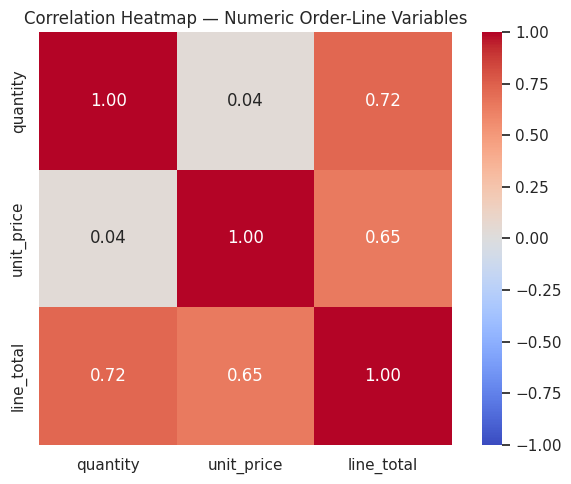

,quantity,unit_price,line_total
quantity,1.000000,0.037589,0.720218
unit_price,0.037589,1.000000,0.648078
line_total,0.720218,0.648078,1.000000


In [17]:
numeric_data = order_lines[["quantity", "unit_price", "line_total"]]
correlation_matrix = numeric_data.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax
)
ax.set_title("Correlation Heatmap — Numeric Order-Line Variables")
plt.tight_layout()
plt.show()

display(correlation_matrix)

**Interpret carefully:** `line_total` is calculated from `quantity` and `unit_price`, so correlations involving it are partly driven by that formula. A high correlation here is not an independent discovery and should not be presented as a causal business insight.

**Exercise 9A:** Create a heatmap for `quantity`, `unit_price`, and `line_total`. Which pair has the strongest positive correlation in your output? Explain why that result should be interpreted carefully.

## 10. Interpret charts responsibly

A professional analyst separates **observation**, **interpretation**, and **recommendation**.

- **Observation:** What can be directly seen or measured in the chart?
- **Interpretation:** What might explain the pattern, and what other explanations are possible?
- **Recommendation:** What action should be considered, and what additional evidence is needed?

### Common visualization mistakes
- Using the wrong chart for the question.
- Leaving out titles, units, or labels.
- Using a misleading scale or truncated bar-chart axis.
- Showing too many colors or an unnecessary legend.
- Treating correlation as causation.
- Calling a point an error or outlier without checking it.
- Making business claims from synthetic or incomplete data.
- Confusing order-line counts with unique order counts.

## 11. Integrated AdventureWorks EDA challenge

### Scenario
The operations manager wants a short visual review of the synthetic order-line data.

### Tasks
1. Create a bar chart of total line value by category.
2. Create a line chart of synthetic daily revenue.
3. Plot the distribution of `line_total` with a histogram.
4. Use a boxplot to compare line values by category.
5. Use a countplot to compare order-line records by status.
6. Create a scatterplot of unit price versus line total.
7. Create a correlation heatmap for numeric columns.
8. Write three findings, each separating observation from interpretation.
9. Add one limitation for each finding and propose one follow-up check.

### Acceptance criteria
- Every chart has a clear title and labeled axes.
- Units are included where appropriate.
- Use a chart type that matches the business question.
- Do not claim causation from correlation.
- Clearly identify the data as synthetic and explain relevant limitations.

## 12. Instructor answer key

> **Instructor use:** Let students complete the challenge before revealing the reference solution. The findings below should be based on the charts actually produced, not memorized as universal business conclusions.

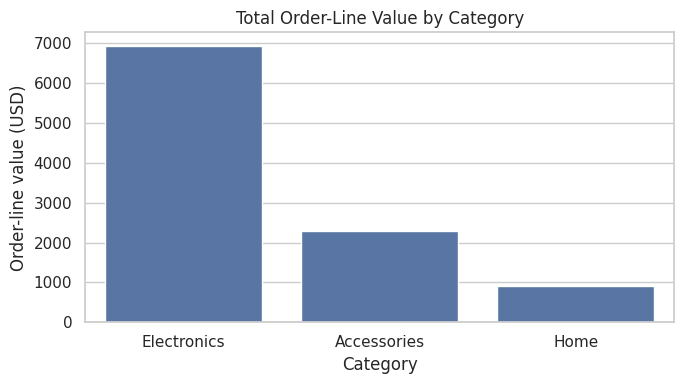

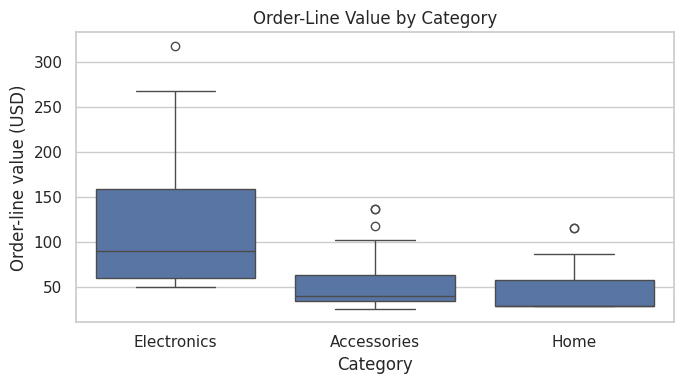

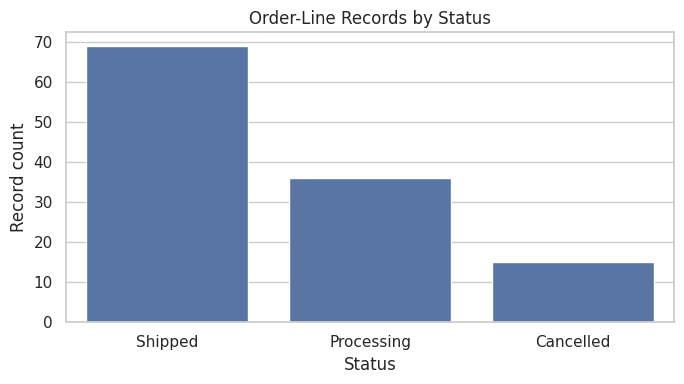

,category,line_total
1,Electronics,6927.35
0,Accessories,2300.79
2,Home,920.00


In [18]:
# Reference plotting workflow
# 1. Category comparison
category_value = (
    order_lines.groupby("category", as_index=False)["line_total"]
    .sum()
    .sort_values("line_total", ascending=False)
)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=category_value, x="category", y="line_total", color="C0", ax=ax)
ax.set_title("Total Order-Line Value by Category")
ax.set_xlabel("Category")
ax.set_ylabel("Order-line value (USD)")
plt.tight_layout()
plt.show()

# 2. Distribution and group comparison
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=order_lines, x="category", y="line_total", ax=ax)
ax.set_title("Order-Line Value by Category")
ax.set_xlabel("Category")
ax.set_ylabel("Order-line value (USD)")
plt.tight_layout()
plt.show()

# 3. Status counts
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=order_lines, x="status", color="C0", ax=ax)
ax.set_title("Order-Line Records by Status")
ax.set_xlabel("Status")
ax.set_ylabel("Record count")
plt.tight_layout()
plt.show()

display(category_value)

### Instructor discussion prompts
- Which chart best answers a ranking question? Why?
- How does the histogram help in a way that the bar chart does not?
- What additional variables could explain differences in order-line value?
- Which statements are directly supported by the data, and which are hypotheses?
- What would need to change before these charts could support a real operational decision?